# Experiment 09 — Random Forest and class imbalance


**Research question:** How do class weighting and resampling affect Random Forest, and are their effects consistent with Logistic Regression?

Compare five configurations using the same split, sampling ratio and evaluation procedure as Experiment 08. Tree settings remain fixed. Each imbalance treatment is applied separately. The test split has already been examined, so results are descriptive; do not tune on them.


## 1. Setup
Keep the original forest settings: 100 trees, maximum depth 12 and at least two samples per leaf. Use a fraud-to-normal sampling ratio of 0.10 and seed 42, matching Experiment 08.

In [11]:
import sys
import json
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    roc_auc_score, roc_curve, auc
)

import imblearn
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

SEED = 42
SAMPLING_RATIO = 0.10
ALERT_BUDGET = 50
RF_PARAMS = {
    "n_estimators": 100,
    "max_depth": 12,
    "min_samples_leaf": 2,
    "max_features": "sqrt",
    "random_state": SEED,
    "n_jobs": -1
}

root = Path.cwd()
if not (root / "data/raw/creditcard.csv").is_file():
    root = root.parent
DATA_PATH = root / "data/raw/creditcard.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Open the notebook inside the existing project with data/raw/creditcard.csv.")

TABLE_DIR = root / "results/tables"
FIGURE_DIR = root / "results/figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("Dataset:", DATA_PATH)

Python: /Users/tankarajjoshi/anaconda3/envs/fraud-mining/bin/python3.11
scikit-learn: 1.9.1
imbalanced-learn: 0.14.2
Dataset: /Users/tankarajjoshi/Projects/credit-card-fraud-extreme-imbalance/data/raw/creditcard.csv


## 2. Load and clean data
Follow Experiment 08 exactly. Remove exact duplicate rows and keep all 30 input features. The absence of transaction identifiers means we cannot prove that identical records were repeated real-world transactions.

In [12]:
df = pd.read_csv(DATA_PATH)
expected_columns = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
assert set(df.columns) == set(expected_columns), "Unexpected dataset columns."
assert not df.isna().any().any(), "Unexpected missing values; inspect before proceeding."
assert set(df["Class"].unique()) == {0, 1}, "Expected binary class labels 0 and 1."

df_clean = df.drop_duplicates().copy()
print("Original transactions:", len(df))
print("Duplicates removed:", len(df) - len(df_clean))
print("Cleaned transactions:", len(df_clean))
print(df_clean["Class"].value_counts().sort_index())

X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

Original transactions: 284807
Duplicates removed: 1081
Cleaned transactions: 283726
Class
0    283253
1       473
Name: count, dtype: int64


## 3. Training, validation and test split
Use the same stratified 80/10/10 split and training-fitted scaler as Experiment 08. Trees do not require standardization, but SMOTE uses distances, so the common scaled feature space ensures its input matches Experiment 08. Validation and test data are never resampled.

In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

split_summary = pd.DataFrame([
    {"Split": name, "Total": len(labels), "Normal": int((labels == 0).sum()),
     "Fraud": int((labels == 1).sum()), "Fraud %": 100 * labels.mean()}
    for name, labels in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]
]).set_index("Split")
display(split_summary.round(4))

expected = [(226980, 378), (28373, 48), (28373, 47)]
actual = [(len(labels), int(labels.sum())) for labels in [y_train, y_val, y_test]]
if actual != expected:
    print("WARNING: Split counts differ from Notebook 07. Verify dataset before comparing results.")
else:
    print("Split counts match Notebook 07.")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

,Total,Normal,Fraud,Fraud %
Split,,,,
Training,226980,226602,378,0.1665
Validation,28373,28325,48,0.1692
Test,28373,28326,47,0.1657


Split counts match Notebook 07.


## 4. Train five Random Forest configurations
- Standard: original training data, no class weights.
- Weighted: original data with balanced class weights.
- RUS: randomly remove normal examples.
- ROS: randomly duplicate fraud examples.
- SMOTE: interpolate between fraud examples using five nearest neighbors.

The samplers use the same settings as Experiment 08. Only training data are resampled. Class weighting is not combined with resampling.

In [14]:
configurations = [
    ("Standard RF", None, None),
    ("Weighted RF", None, "balanced"),
    ("RUS + RF", RandomUnderSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED), None),
    ("ROS + RF", RandomOverSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED), None),
    ("SMOTE + RF", SMOTE(sampling_strategy=SAMPLING_RATIO, random_state=SEED, k_neighbors=5), None)
]

models = {}
training_rows = []
val_scores = {}

for name, sampler, class_weight in configurations:
    start = perf_counter()
    if sampler is None:
        X_fit, y_fit = X_train_scaled, y_train
    else:
        X_fit, y_fit = sampler.fit_resample(X_train_scaled, y_train)
    sampling_seconds = perf_counter() - start

    model = RandomForestClassifier(**RF_PARAMS, class_weight=class_weight)
    print(f"Training {name} ...", flush=True)
    start = perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start

    normal = int((y_fit == 0).sum())
    fraud = int((y_fit == 1).sum())
    training_rows.append({
        "Model": name, "Normal": normal, "Fraud": fraud,
        "Total": normal + fraud, "Fraud/Normal": fraud / normal,
        "Sampling seconds": sampling_seconds, "Fit seconds": fit_seconds,
        "Trees": model.n_estimators
    })
    models[name] = model
    val_scores[name] = model.predict_proba(X_val_scaled)[:, 1]
    print(f"{name}: {normal:,} normal, {fraud:,} fraud | fit: {fit_seconds:.2f} seconds", flush=True)
    del X_fit, y_fit

training_summary = pd.DataFrame(training_rows).set_index("Model")
display(training_summary.round(4))

Training Standard RF ...
Standard RF: 226,602 normal, 378 fraud | fit: 16.48 seconds
Training Weighted RF ...
Weighted RF: 226,602 normal, 378 fraud | fit: 8.73 seconds
Training RUS + RF ...
RUS + RF: 3,780 normal, 378 fraud | fit: 0.21 seconds
Training ROS + RF ...
ROS + RF: 226,602 normal, 22,660 fraud | fit: 17.46 seconds
Training SMOTE + RF ...
SMOTE + RF: 226,602 normal, 22,660 fraud | fit: 17.19 seconds


,Normal,Fraud,Total,Fraud/Normal,Sampling seconds,Fit seconds,Trees
Model,,,,,,,
Standard RF,226602,378,226980,0.0017,0.0000,16.4789,100
Weighted RF,226602,378,226980,0.0017,0.0000,8.7300,100
RUS + RF,3780,378,4158,0.1000,0.0302,0.2111,100
ROS + RF,226602,22660,249262,0.1000,0.0349,17.4645,100
SMOTE + RF,226602,22660,249262,0.1000,0.0390,17.1868,100


## 5. Choose thresholds using validation data
Select the threshold that maximizes F1 on validation data using the same procedure as Notebook 08. AP and trapezoidal PR-AUC are reported separately. The model scores are not necessarily calibrated fraud probabilities.

In [15]:
def find_best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    precision = precision[:-1]
    recall = recall[:-1]
    f1 = 2 * precision * recall / (precision + recall + 1e-10)
    return float(thresholds[np.argmax(f1)])


def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    (tp, fn), (fp, tn) = confusion_matrix(y_true, predictions, labels=[1, 0])
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        "Threshold": threshold,
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "AP": average_precision_score(y_true, probabilities),
        "PR-AUC": auc(recall, precision),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Alerts": int(tp + fp),
        "Alerts per 1000": 1000 * (tp + fp) / len(y_true)
    }


def evaluate_alert_budget(y_true, probabilities, budget=ALERT_BUDGET):
    labels = np.asarray(y_true)
    k = min(budget, len(labels))
    top = np.argsort(-probabilities, kind="stable")[:k]
    tp = int(labels[top].sum())
    return {
        "Alert budget": k,
        "Fraud detected": tp,
        "False alarms": k - tp,
        "Precision@50": tp / k,
        "Recall@50": tp / labels.sum(),
        "Scores tied at cutoff": int(np.sum(probabilities == probabilities[top[-1]]))
    }

thresholds = {name: find_best_threshold(y_val, scores)
              for name, scores in val_scores.items()}
validation_results = pd.DataFrame.from_dict({
    name: evaluate_model(y_val, scores, thresholds[name])
    for name, scores in val_scores.items()
}, orient="index")
validation_results.index.name = "Model"

display(validation_results.round(6))
print("Highest validation F1:", validation_results["F1"].idxmax())
print("Highest validation AP:", validation_results["AP"].idxmax())

,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,PR-AUC,ROC-AUC,Alerts,Alerts per 1000
Model,,,,,,,,,,,,,
Standard RF,0.489621,34,14,1,28324,0.971429,0.708333,0.819277,0.752995,0.752686,0.956713,35,1.233567
Weighted RF,0.614483,34,14,2,28323,0.944444,0.708333,0.809524,0.781524,0.781213,0.954111,36,1.268812
RUS + RF,0.691515,36,12,8,28317,0.818182,0.750000,0.782609,0.668864,0.693872,0.946026,44,1.550770
ROS + RF,0.439685,34,14,2,28323,0.944444,0.708333,0.809524,0.782107,0.781862,0.962180,36,1.268812
SMOTE + RF,0.564186,35,13,3,28322,0.921053,0.729167,0.813953,0.788703,0.788386,0.971847,38,1.339301


Highest validation F1: Standard RF
Highest validation AP: SMOTE + RF


## 6. Evaluate the fixed models
Use the validation-selected thresholds without adjustment. Report false alarms and the number of alerts as well as precision, recall, F1, AP, PR-AUC and ROC-AUC. At a fixed budget of 50 alerts, rank scores from highest to lowest. Ties are resolved by the existing test row order, not the true labels. The table also reports how many scores equal the cutoff, because tied tree scores can affect the top-50 result.

In [16]:
test_scores = {name: model.predict_proba(X_test_scaled)[:, 1]
               for name, model in models.items()}

test_results = pd.DataFrame.from_dict({
    name: evaluate_model(y_test, scores, thresholds[name])
    for name, scores in test_scores.items()
}, orient="index")
test_results.index.name = "Model"

alert_results = pd.DataFrame.from_dict({
    name: evaluate_alert_budget(y_test, scores)
    for name, scores in test_scores.items()
}, orient="index")
alert_results.index.name = "Model"

print("Test results at validation-selected thresholds:")
display(test_results.round(6))
print("Test comparison at the same 50-alert budget:")
display(alert_results.round(6))

# Check confusion-matrix totals and unchanged validation thresholds.
assert (test_results[["TP", "FN", "FP", "TN"]].sum(axis=1) == len(y_test)).all()
assert (test_results["TP"] + test_results["FN"] == y_test.sum()).all()
assert np.array_equal(test_results["Threshold"].to_numpy(), validation_results["Threshold"].to_numpy())

Test results at validation-selected thresholds:


,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,PR-AUC,ROC-AUC,Alerts,Alerts per 1000
Model,,,,,,,,,,,,,
Standard RF,0.489621,37,10,1,28325,0.973684,0.787234,0.870588,0.834126,0.833668,0.986807,38,1.339301
Weighted RF,0.614483,36,11,3,28323,0.923077,0.765957,0.837209,0.836332,0.835673,0.979514,39,1.374546
RUS + RF,0.691515,38,9,11,28315,0.775510,0.808511,0.791667,0.695215,0.733106,0.983421,49,1.726994
ROS + RF,0.439685,37,10,3,28323,0.925000,0.787234,0.850575,0.843708,0.843227,0.977476,40,1.409791
SMOTE + RF,0.564186,37,10,5,28321,0.880952,0.787234,0.831461,0.837968,0.837388,0.983840,42,1.480281


Test comparison at the same 50-alert budget:


,Alert budget,Fraud detected,False alarms,Precision@50,Recall@50,Scores tied at cutoff
Model,,,,,,
Standard RF,50,39,11,0.78,0.829787,1
Weighted RF,50,38,12,0.76,0.808511,1
RUS + RF,50,38,12,0.76,0.808511,1
ROS + RF,50,39,11,0.78,0.829787,1
SMOTE + RF,50,38,12,0.76,0.808511,1


## 7. Compare with Logistic Regression
Read the saved Experiment 08 results if available and show the five treatments side by side. This assumes the same input file, row order, and seed. Matching split counts alone do not prove sample identity. Do not use test comparisons to change settings.

In [17]:
columns = ["TP", "FN", "FP", "Precision", "Recall", "F1", "AP", "ROC-AUC", "Alerts"]
lr_path = TABLE_DIR / "08_lr_test_comparison.csv"
lr_split_path = TABLE_DIR / "08_split_summary.csv"

if lr_path.is_file() and lr_split_path.is_file():
    lr_split = pd.read_csv(lr_split_path, index_col="Split")
    if lr_split[["Total", "Normal", "Fraud"]].equals(
        split_summary[["Total", "Normal", "Fraud"]]
    ):
        lr_results = pd.read_csv(lr_path, index_col="Model")
        comparison = pd.concat([lr_results[columns], test_results[columns]])
        display(comparison.round(4))

        treatments = ["Standard", "Class weighting", "RUS", "ROS", "SMOTE"]
        lr_order = ["Standard LR", "Weighted LR", "RUS + LR", "ROS + LR", "SMOTE + LR"]
        rf_order = ["Standard RF", "Weighted RF", "RUS + RF", "ROS + RF", "SMOTE + RF"]
        for metric in ["F1", "AP"]:
            print(f"Test {metric} by treatment:")
            display(pd.DataFrame({
                "Logistic Regression": lr_results.loc[lr_order, metric].to_numpy(),
                "Random Forest": test_results.loc[rf_order, metric].to_numpy()
            }, index=treatments).round(4))
    else:
        print("Experiment 08 split counts differ; compare only after checking the dataset.")
else:
    print("Experiment 08 CSV files not found. Random Forest results are available above.")

,TP,FN,FP,Precision,Recall,F1,AP,ROC-AUC,Alerts
Model,,,,,,,,,
Standard LR,37,10,9,0.8043,0.7872,0.7957,0.7447,0.9807,46
Weighted LR,38,9,8,0.8261,0.8085,0.8172,0.6991,0.9847,46
RUS + LR,37,10,6,0.8605,0.7872,0.8222,0.6734,0.9837,43
ROS + LR,39,8,12,0.7647,0.8298,0.7959,0.7315,0.9840,51
SMOTE + LR,38,9,11,0.7755,0.8085,0.7917,0.7295,0.9849,49
Standard RF,37,10,1,0.9737,0.7872,0.8706,0.8341,0.9868,38
Weighted RF,36,11,3,0.9231,0.7660,0.8372,0.8363,0.9795,39
RUS + RF,38,9,11,0.7755,0.8085,0.7917,0.6952,0.9834,49
ROS + RF,37,10,3,0.9250,0.7872,0.8506,0.8437,0.9775,40


Test F1 by treatment:


,Logistic Regression,Random Forest
Standard,0.7957,0.8706
Class weighting,0.8172,0.8372
RUS,0.8222,0.7917
ROS,0.7959,0.8506
SMOTE,0.7917,0.8315


Test AP by treatment:


,Logistic Regression,Random Forest
Standard,0.7447,0.8341
Class weighting,0.6991,0.8363
RUS,0.6734,0.6952
ROS,0.7315,0.8437
SMOTE,0.7295,0.8380


## 8. Test metrics and confusion matrices
Compare precision, recall, F1 and AP. Fraud is the first row and column of each confusion matrix.

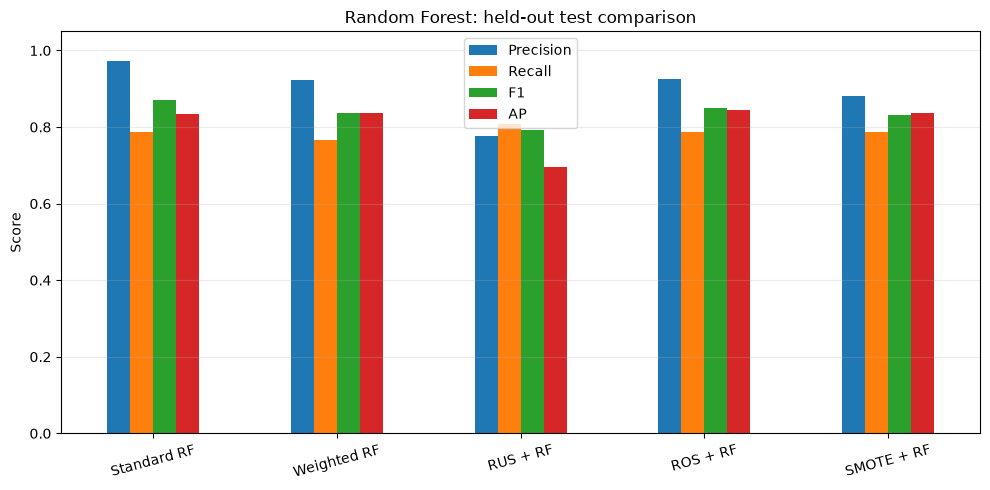

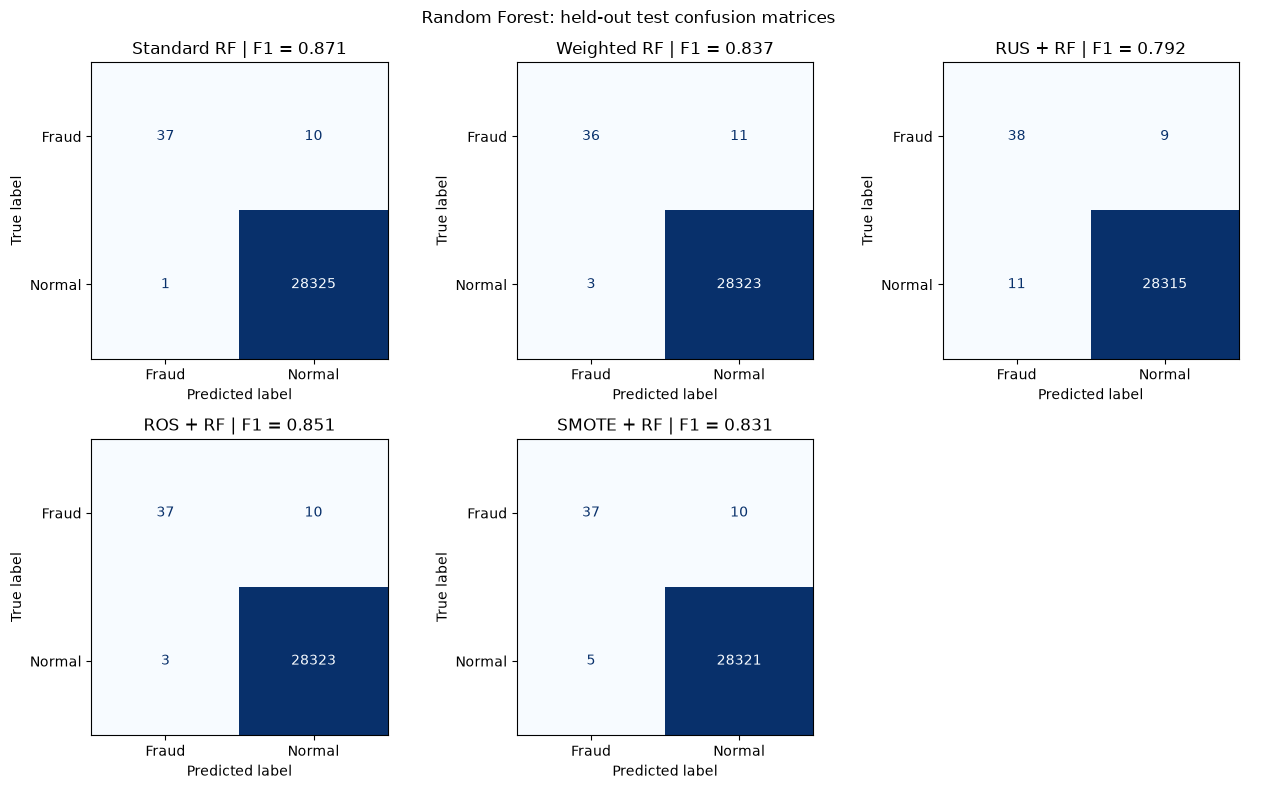

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
test_results[["Precision", "Recall", "F1", "AP"]].plot.bar(ax=ax, rot=15)
ax.set_title("Random Forest: held-out test comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_rf_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, scores) in zip(axes.flat, test_scores.items()):
    predictions = (scores >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, predictions, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["Fraud", "Normal"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{name} | F1 = {test_results.loc[name, 'F1']:.3f}")
axes.flat[-1].axis("off")
fig.suptitle("Random Forest: held-out test confusion matrices")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_rf_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Precision-recall and ROC curves
Compare ranking performance across thresholds. The PR baseline is the fraud prevalence; the ROC baseline is the diagonal.

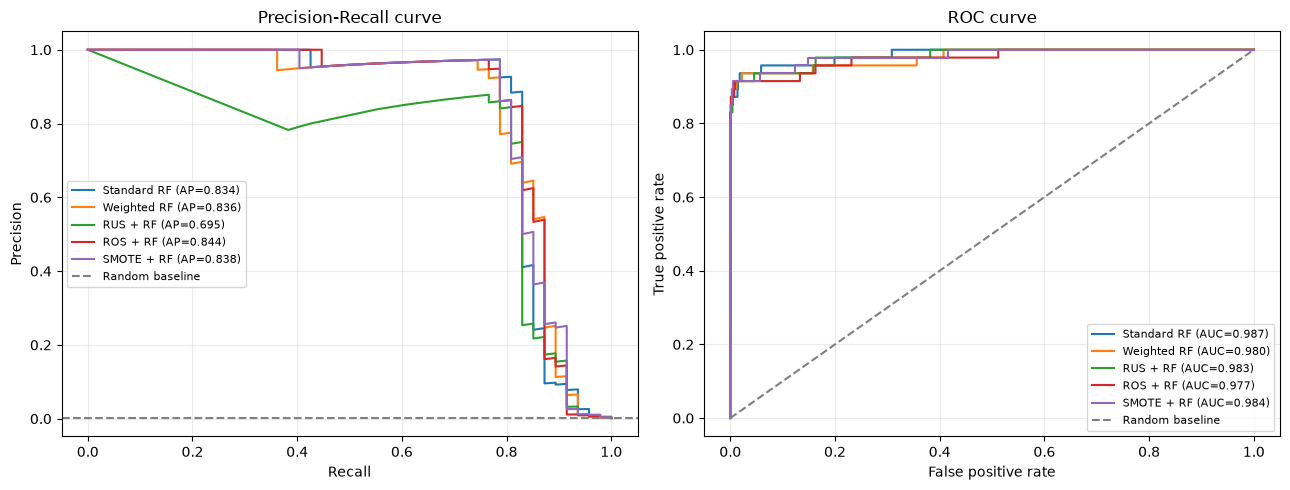

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, label=f"{name} (AP={test_results.loc[name, 'AP']:.3f})")
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={test_results.loc[name, 'ROC-AUC']:.3f})")

axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="Random baseline")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random baseline")
axes[0].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
axes[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_rf_pr_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Save results
Save aggregate results and model settings for reproducibility. No raw data, individual predictions or trained models are exported.

In [22]:
for filename, table in {
    "09_split_summary.csv": split_summary,
    "09_rf_training_summary.csv": training_summary,
    "09_rf_validation_comparison.csv": validation_results,
    "09_rf_test_comparison.csv": test_results,
    "09_rf_alert_budget.csv": alert_results
}.items():
    table.to_csv(TABLE_DIR / filename, float_format="%.17g")

settings = {
    "seed": SEED,
    "split": [0.8, 0.1, 0.1],
    "remove_exact_duplicates": True,
    "scaling": "StandardScaler fitted on original training data only",
    "sampling_strategy": SAMPLING_RATIO,
    "smote_k_neighbors": 5,
    "samplers": {name: None if sampler is None else {
        "name": type(sampler).__name__, "parameters": sampler.get_params()
    } for name, sampler, _ in configurations},
    "threshold_selection": "Maximum validation F1; first maximum in ascending threshold order",
    "alert_budget": ALERT_BUDGET,
    "alert_tie_break": "Stable descending score sort, original test row order",
    "model_parameters": {name: model.get_params() for name, model in models.items()},
    "selected_thresholds": thresholds,
    "versions": {
        "python": sys.version.split()[0], "numpy": np.__version__,
        "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
        "imbalanced-learn": imblearn.__version__
    }
}
(TABLE_DIR / "09_rf_experiment_config.json").write_text(json.dumps(settings, indent=2))

for folder in [TABLE_DIR, FIGURE_DIR]:
    for path in sorted(folder.glob("09_*")):
        print(path.relative_to(root), f"({path.stat().st_size:,} bytes)")

results/tables/09_rf_alert_budget.csv (400 bytes)
results/tables/09_rf_experiment_config.json (4,159 bytes)
results/tables/09_rf_test_comparison.csv (1,018 bytes)
results/tables/09_rf_training_summary.csv (547 bytes)
results/tables/09_rf_validation_comparison.csv (1,004 bytes)
results/tables/09_split_summary.csv (166 bytes)
results/figures/09_rf_confusion_matrices.png (216,490 bytes)
results/figures/09_rf_metric_comparison.png (95,021 bytes)
results/figures/09_rf_pr_roc_curves.png (247,224 bytes)


## Conclusion

Five Random Forest configurations were evaluated using the same dataset splits, sampling ratio, and threshold-selection procedure as the Logistic Regression experiments.

Standard Random Forest achieved the highest test F1-score of 87.06% and precision of 97.37%, with only one false alarm. Random Oversampling achieved the highest Average Precision of 0.8437.

Undersampling improved Logistic Regression in terms of F1-score but reduced Random Forest performance. However, it substantially reduced Random Forest training time.

Under a fixed budget of 50 alerts, all configurations detected between 38 and 39 fraud transactions.

These results suggest that the effectiveness of imbalance-handling techniques depends on the learning algorithm and evaluation metric. Since the test set contains only 47 fraud transactions, further cross-validation is needed to assess the stability of these findings.